# 08 — LEVIR ROI Model Selection | Part 1: Medium diagnosis and integration audit

**Research I. Status: preflight and Medium diagnosis — not yet the full ROI study.** This part establishes whether the existing results justify threshold/post-processing changes, or whether additional validation across training seeds and new training experiments are necessary. It identifies existing `satchange` interfaces and collects missing project context **before writing any ROI implementation**.

**Safety and methodology:** No automatic training, checkpoint loading, network calls, source edits, or test-set threshold tuning. Original H1–H5 test data were already examined, so the present work is exploratory. The seed validation section is **disabled by default** and, if enabled, uses the exact implementation embedded in notebook 06 and the project's own `satchange` APIs. No replacement model factory, loader, matcher, dataset, or metric implementation is introduced.

**Run in order:** sections 0–6 for existing evidence and an API audit; section 7 only if an additional seed experiment is justified. Send the resulting `08_medium_diagnostic_context.zip` and/or its accompanying summary before implementing Part 2 (ROI selection).

## 0. Configuration

Use the same project root as notebooks 05–07. This notebook reads the **existing** report folders or their exported ZIP archives; it does not silently recompute prior results.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path('/home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence').expanduser()
V1_RUN = 'H1_H5_v1'
FOLLOWUP_RUN = 'H1_H5_followup_v2'
OUTPUT_NAME = '08_medium_diagnostic'
DEVICE = 'cuda:0'  # Only used by the optional seed inference section.

# GPU inference / extra validation, OFF by default:
RUN_MEDIUM_SEED_VALIDATION = False
# Explicitly opt in only for checkpoints you created and trust.
TRUST_OWN_SEED_CHECKPOINTS = False

# Optional explicit paths if reports live outside the project:
V1_ZIP = None
FOLLOWUP_ZIP = None

# Limit context export (no checkpoints, images, binary score caches, secrets).
MAX_EXPORTED_PY_FILES = 100
MAX_EXPORTED_PY_MIB = 12

print('Project:', PROJECT_ROOT)
print('Read-only by default. Seed inference:', RUN_MEDIUM_SEED_VALIDATION)

Project: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence
Read-only by default. Seed inference: False


## 1. Read existing reports safely (from folders or their original ZIP exports)

This section works without GPU access. It uses only immutable reports and their original run manifest. Source selection is explicit in the printed output.

In [2]:
import ast
import hashlib
import io
import json
import re
import sys
import zipfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = PROJECT_ROOT.resolve()
OUT = (PROJECT_ROOT if PROJECT_ROOT.is_dir() else Path.cwd()) / 'artifacts' / 'hypothesis_tests' / OUTPUT_NAME
OUT.mkdir(parents=True, exist_ok=True)

class ReportReader:
    # Reads a named report file; does not extract an archive to disk.
    def __init__(self, folder, archive, archive_name):
        self.folder = Path(folder)
        candidates = ([Path(archive)] if archive else []) + [
            PROJECT_ROOT / archive_name, PROJECT_ROOT / 'artifacts' / 'hypothesis_tests' / archive_name,
            Path.cwd() / archive_name, Path('/mnt/data') / archive_name,
        ]
        if self.folder.is_dir():
            self.kind, self.source = 'folder', self.folder
        else:
            self.source = next((p for p in candidates if p.is_file()), None)
            if self.source is None:
                raise FileNotFoundError('Missing report folder and archive: ' + archive_name +
                                        '. Set V1_ZIP/FOLLOWUP_ZIP or restore the existing run reports.')
            self.kind = 'zip'
        print(self.kind.upper(), self.source)
    def read(self, relative):
        relative = str(relative).replace('\\', '/')
        if relative.startswith('/') or '..' in Path(relative).parts:
            raise ValueError('Invalid report relative path')
        if self.kind == 'folder':
            return (self.source / relative).read_bytes()
        with zipfile.ZipFile(self.source) as z:
            return z.read(relative)
    def table(self, relative, **kw):
        return pd.read_csv(io.BytesIO(self.read(relative)), **kw)
    def obj(self, relative):
        return json.loads(self.read(relative).decode('utf-8'))

V1 = ReportReader(PROJECT_ROOT / 'artifacts/hypothesis_tests' / V1_RUN,
                  V1_ZIP, 'H1_H5_v1_results.zip')
FOLLOWUP = ReportReader(PROJECT_ROOT / 'artifacts/hypothesis_tests' / FOLLOWUP_RUN,
                        FOLLOWUP_ZIP, 'H1_H5_followup_v2_results.zip')
manifest = V1.obj('run_manifest.json')
frozen = V1.obj('protocol_frozen.json')
if manifest['signature'] != frozen['signature']:
    raise RuntimeError('Original V1 manifest and frozen protocol signatures differ.')
fu_manifest = FOLLOWUP.obj('followup_manifest.json')
if fu_manifest['protocol']['source_signature'] != manifest['signature']:
    raise RuntimeError('The follow-up archive is not derived from this V1 run.')
print('V1 signature:', manifest['signature'][:16])
print('Follow-up signature:', fu_manifest['signature'][:16])
print('Previous test set accessed:', fu_manifest.get('test_previously_seen'))

FOLDER /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_v1
FOLDER /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/H1_H5_followup_v2
V1 signature: d4dd064aba8ca197
Follow-up signature: 907b8ec5d4f6465d
Previous test set accessed: True


## 2. Establish the Medium failure signature

Report the three distinct questions separately: (a) does the model capture pixels, (b) does it match components at IoU ≥ 0.5, and (c) are there excessive multi-object predicted regions? **Coverage ≥ 50% is not ROI coverage**; actual crops have not yet been generated.

In [3]:
cols = ['variant','policy','threshold','pixel_precision','pixel_recall','pixel_f1',
        'object_recall_010','object_recall_025','object_recall_050',
        'gt_coverage_recall_050','completely_missed_fraction','alerts_per_pair']
frames = []
for split in ('val','test'):
    frame = V1.table(f'reports/{split}_summary.csv')
    frame = frame[(frame['primary'].astype(str).str.lower() == 'true') & (frame['policy']=='val_f1')].copy()
    frame['split'] = split
    frames.append(frame[['split']+cols])
baseline = pd.concat(frames, ignore_index=True)
print('Existing validation-frozen operating points (test is descriptive only):')
display(baseline.round(4))
baseline.to_csv(OUT/'baseline_summary.csv', index=False)

# Computed from existing report columns; descriptive diagnostic, not a model ranking criterion.
medium = baseline[baseline.variant.str.startswith('medium_')].copy()
medium['covered_but_not_iou_matched_lower_bound'] = (
    medium['gt_coverage_recall_050'] - medium['object_recall_050']
).clip(lower=0)
print('Medium: gap between >=50%-covered components and IoU-matched components')
display(medium[['split','variant','threshold','pixel_f1','pixel_recall',
                'object_recall_050','gt_coverage_recall_050',
                'covered_but_not_iou_matched_lower_bound','completely_missed_fraction']].round(4))

Existing validation-frozen operating points (test is descriptive only):


,split,variant,policy,threshold,pixel_precision,pixel_recall,pixel_f1,object_recall_010,object_recall_025,object_recall_050,gt_coverage_recall_050,completely_missed_fraction,alerts_per_pair
0,val,light_full,val_f1,0.80,0.8455,0.8564,0.8509,0.8429,0.8311,0.7647,0.8892,0.0803,45.3438
1,val,light_resized,val_f1,0.63,0.7548,0.7583,0.7565,0.4778,0.4308,0.3171,0.7981,0.1410,26.6719
2,val,medium_full,val_f1,0.69,0.8644,0.8576,0.8610,0.7529,0.7324,0.6431,0.8730,0.0857,37.5781
3,val,medium_resized,val_f1,0.68,0.6735,0.7704,0.7187,0.2105,0.1445,0.0735,0.7859,0.1288,13.0938
4,val,heavy_full,val_f1,0.81,0.8683,0.8722,0.8702,0.8619,0.8468,0.7927,0.8906,0.0735,43.3594
5,val,heavy_resized,val_f1,0.81,0.7614,0.7912,0.7760,0.4024,0.3497,0.2518,0.8128,0.1313,20.4688
6,test,light_full,val_f1,0.80,0.8339,0.8485,0.8411,0.8275,0.8107,0.7327,0.9099,0.0616,57.7812
7,test,light_resized,val_f1,0.63,0.7440,0.7752,0.7593,0.4493,0.3962,0.2784,0.8342,0.1027,30.9062
8,test,medium_full,val_f1,0.69,0.8616,0.8354,0.8483,0.7208,0.6912,0.5929,0.8816,0.0699,45.2344
9,test,medium_resized,val_f1,0.68,0.6636,0.7553,0.7065,0.1766,0.1123,0.0495,0.8153,0.1056,14.6172


Medium: gap between >=50%-covered components and IoU-matched components


,split,variant,threshold,pixel_f1,pixel_recall,object_recall_050,gt_coverage_recall_050,covered_but_not_iou_matched_lower_bound,completely_missed_fraction
2,val,medium_full,0.69,0.8610,0.8576,0.6431,0.8730,0.2299,0.0857
3,val,medium_resized,0.68,0.7187,0.7704,0.0735,0.7859,0.7123,0.1288
8,test,medium_full,0.69,0.8483,0.8354,0.5929,0.8816,0.2887,0.0699
9,test,medium_resized,0.68,0.7065,0.7553,0.0495,0.8153,0.7658,0.1056


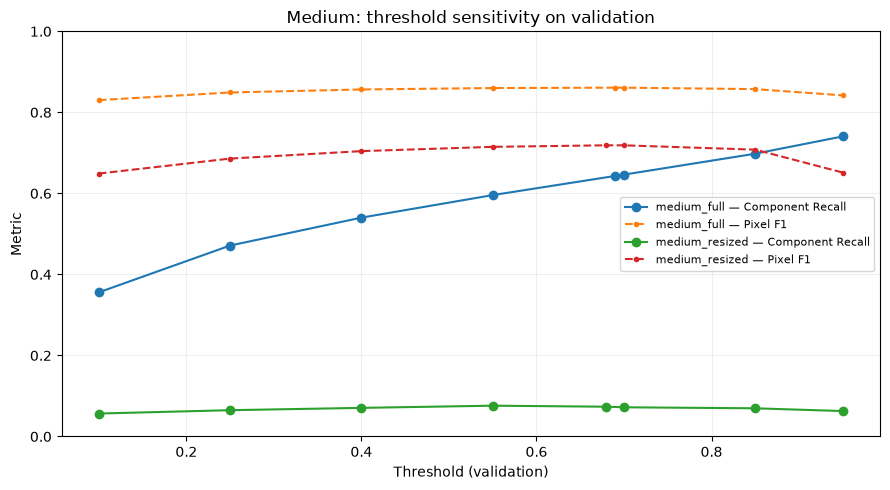

Known validation sweep (not a complete 0–1 scan):


,split,variant,threshold,alerts_per_pair,false_alerts_per_pair,components_per_pair,pixel_f1,pixel_precision,pixel_recall,component_recall,component_precision
32,val,medium_full,0.10,30.4375,14.9375,43.5625,0.8302,0.7488,0.9315,0.3558,0.5092
33,val,medium_full,0.25,32.9531,12.4219,43.5625,0.8491,0.7975,0.9078,0.4713,0.6230
34,val,medium_full,0.40,34.9375,11.4062,43.5625,0.8565,0.8243,0.8913,0.5402,0.6735
35,val,medium_full,0.55,36.3594,10.4062,43.5625,0.8600,0.8453,0.8752,0.5958,0.7138
36,val,medium_full,0.69,37.5781,9.5625,43.5625,0.8610,0.8644,0.8576,0.6431,0.7455
37,val,medium_full,0.70,37.5938,9.4375,43.5625,0.8609,0.8658,0.8561,0.6463,0.7490
38,val,medium_full,0.85,38.9531,8.5469,43.5625,0.8574,0.8910,0.8263,0.6980,0.7806
39,val,medium_full,0.95,40.1406,7.8750,43.5625,0.8420,0.9203,0.7759,0.7407,0.8038
40,val,medium_resized,0.10,16.3438,13.8750,43.5625,0.6490,0.5086,0.8963,0.0567,0.1511
41,val,medium_resized,0.25,14.7500,11.9219,43.5625,0.6859,0.5688,0.8639,0.0649,0.1917


In [4]:
sweep = FOLLOWUP.table('reports/H4_H5_validation_threshold_sweep.csv')
sweep = sweep[sweep.variant.isin(['medium_full','medium_resized'])].copy()
assert sweep.split.eq('val').all(), 'Threshold sweep MUST be validation-only.'
fig, ax = plt.subplots(figsize=(9,5))
for name, group in sweep.groupby('variant'):
    group = group.sort_values('threshold')
    ax.plot(group.threshold, group.component_recall, marker='o', label=f'{name} — Component Recall')
    ax.plot(group.threshold, group.pixel_f1, linestyle='--', marker='.', label=f'{name} — Pixel F1')
ax.set(xlabel='Threshold (validation)', ylabel='Metric', title='Medium: threshold sensitivity on validation')
ax.set_ylim(0,1); ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'medium_validation_thresholds.png', dpi=150)
plt.show(); plt.close(fig)
print('Known validation sweep (not a complete 0–1 scan):')
display(sweep.sort_values(['variant','threshold']).round(4))
sweep.to_csv(OUT/'medium_validation_threshold_sweep.csv',index=False)

In [5]:
modes = []
topology = []
for split in ('val','test'):
    x = FOLLOWUP.table(f'reports/H4_{split}_component_failure_modes.csv')
    x['split'] = split
    modes.append(x[x.variant.isin(['medium_full','medium_resized'])].copy())
    y = FOLLOWUP.table(f'reports/H4_{split}_overlap_topology_counts.csv')
    y['split'] = split
    topology.append(y[y.variant.isin(['medium_full','medium_resized'])].copy())
modes = pd.concat(modes,ignore_index=True)
topology = pd.concat(topology,ignore_index=True)
mode_totals = (modes.groupby(['split','variant','failure_mode'],as_index=False)
                 .agg(components=('gt_components','sum')))
mode_totals['share'] = mode_totals['components'] / mode_totals.groupby(['split','variant']).components.transform('sum')
print('Failure modes, pooled across GT area bins:')
display(mode_totals.pivot_table(index=['split','variant'],columns='failure_mode',values='share').round(4))
print('Overlap topology counts (an overlap is not by itself proof of an error mechanism):')
display(topology)
mode_totals.to_csv(OUT/'medium_failure_modes.csv',index=False)
topology.to_csv(OUT/'medium_overlap_topology.csv',index=False)

Failure modes, pooled across GT area bins:


failure_mode          covered_at_least_half_but_unmatched  matched_iou_050  \
split variant                                                                
test  medium_full                                  0.2887           0.5929   
      medium_resized                               0.7658           0.0495   
val   medium_full                                  0.2299           0.6431   
      medium_resized                               0.7123           0.0735   

failure_mode          partially_covered_below_half  zero_coverage  
split variant                                                      
test  medium_full                           0.0485         0.0699  
      medium_resized                        0.0791         0.1056  
val   medium_full                           0.0412         0.0857  
      medium_resized                        0.0854         0.1288

Overlap topology counts (an overlap is not by itself proof of an error mechanism):


,variant,gt_with_multiple_overlapping_pred_components,pred_components_overlapping_multiple_gt,n_gt,n_pred,split
0,medium_full,54,254,2788,2405,val
1,medium_resized,8,351,2788,838,val
2,medium_full,162,717,7027,5790,test
3,medium_resized,37,903,7027,1871,test


## 3. Model configuration, training seeds and HPO provenance

Full versus Resized BIT do not only differ in resolution. This section checks the actual archived model parameters and whether different seeds were **evaluated** (having three weight files is not evidence of seed stability). It also inventories local HPO records if accessible.

In [6]:
specs = [s for s in manifest['protocol']['specs'] if s['variant'].startswith('medium_') and s['primary']]
model_table = pd.DataFrame([{
    'variant':s['variant'], 'architecture':s['model_name'], 'image_size':s['image_size'],
    'seed_selected':s['seed'],'seed_files_reported':s['available_seed_files'],
    **{f'model_{k}':v for k,v in s['model_parameters'].items()}
} for s in specs])
print('Medium configuration from original immutable run manifest:')
display(model_table.T)
model_table.to_csv(OUT/'medium_architecture.csv',index=False)
seed_report = V1.table('reports/test_seed_sensitivity.csv')
seed_report = seed_report[seed_report.variant.str.startswith('medium_')]
print('Number of seeds ACTUALLY evaluated in prior test archive:')
display(seed_report[['variant','metric','n_seeds_evaluated','mean','sample_sd_ddof1']])

# Read JSON metadata only. Do not import training backend or load weights.
media = []
for variant in ('medium_full','medium_resized'):
    folder=PROJECT_ROOT/'artifacts/final_models'/variant
    record={'variant':variant, 'directory_exists':folder.is_dir()}
    for name in ('metadata.json','benchmark.json','training_results.json','validation_results.json','final_test_results.json'):
        p=folder/name
        record[name+'_present']=p.is_file()
        if p.is_file():
            try:
                obj=json.loads(p.read_text(encoding='utf-8'))
                record[name+'_keys']=','.join(sorted(obj.keys())) if isinstance(obj,dict) else type(obj).__name__
            except Exception as exc:
                record[name+'_error']=f'{type(exc).__name__}: {exc}'
    record['available_seed_weights']=[p.name for p in sorted(folder.glob('seed_*_best.pt'))]
    record['deployment_weights_present']=(folder/'deployment_weights.pt').is_file()
    media.append(record)
medium_local_inventory=pd.DataFrame(media)
display(medium_local_inventory.T)
medium_local_inventory.to_csv(OUT/'medium_local_artifacts.csv',index=False)

Medium configuration from original immutable run manifest:


,0,1
variant,medium_full,medium_resized
architecture,bit,bit
image_size,1024,256
seed_selected,123,123
seed_files_reported,"[42, 123, 777]","[42, 123, 777]"
model_decoder_depth,8,8
model_decoder_head_dim,64,64
model_dropout,0.0,0.0
model_embedding_dim,64,32
model_encoder_depth,1,1


Number of seeds ACTUALLY evaluated in prior test archive:


,variant,metric,n_seeds_evaluated,mean,sample_sd_ddof1
16,medium_full,pixel_f1,1,0.848278,NaN
17,medium_full,pixel_recall,1,0.835379,NaN
18,medium_full,object_recall_050,1,0.592856,NaN
19,medium_full,boundary_iou,1,0.275831,NaN
20,medium_resized,pixel_f1,1,0.706489,NaN
21,medium_resized,pixel_recall,1,0.755267,NaN
22,medium_resized,object_recall_050,1,0.049523,NaN
23,medium_resized,boundary_iou,1,0.092448,NaN


,0,1
variant,medium_full,medium_resized
directory_exists,True,True
metadata.json_present,True,True
metadata.json_keys,"deployment_best_epoch,deployment_seed,deployme...","dataset_root,deployment_best_epoch,deployment_..."
benchmark.json_present,True,True
benchmark.json_keys,"checkpoint_mb,cuda_version,device,gpu_name,lat...","checkpoint_mb,checkpoint_sizes_mib,cuda_versio..."
training_results.json_present,True,True
training_results.json_keys,"model_name,number_of_trials,results,search_names","model_name,number_of_trials,results,search_nam..."
validation_results.json_present,True,True
validation_results.json_keys,"evaluation_batch_size,image_size,model,number_...","evaluation_batch_size,historical_backend_note,..."


## 4. Audit existing project functionality — inspect APIs, do not reimplement them

The uploaded 06 and 07 notebooks include a snapshot of their analysis code, but **they do not include the current `src/satchange` repository**. This audit reads the live project source and lists candidate functions for model creation, inference, thresholding, ROI/cropping, and HPO. It does not edit or execute source files.

In [7]:
SRC = PROJECT_ROOT/'src/satchange'
expected = {
    'satchange.data.levir_cd':('LEVIRCDDataset',),
    'satchange.models':('create_change_model',),
    'satchange.final_benchmark':('_runtime','_load_checkpoint','_instantiate'),
    'satchange.automated_hpo':('run_automated_parameter_search',),
}
source_rows=[]
keywords=('roi','crop','bounding','component','mask','threshold','inference','hpo','predict','ensemble')
if SRC.is_dir():
    for path in sorted(SRC.rglob('*.py')):
        if any(x in path.parts for x in ('__pycache__','source_backups')):
            continue
        try:
            content=path.read_text(encoding='utf-8')
            tree=ast.parse(content,filename=str(path))
            defs=[]
            for node in ast.walk(tree):
                if isinstance(node,(ast.FunctionDef,ast.AsyncFunctionDef,ast.ClassDef)):
                    defs.append(node.name)
            module='satchange.'+'.'.join(path.relative_to(SRC).with_suffix('').parts)
            hits=sorted({x for x in defs if any(k in x.lower() for k in keywords)})
            source_rows.append({'path':path.relative_to(PROJECT_ROOT).as_posix(),
                                'module':module,'sha256':hashlib.sha256(content.encode()).hexdigest(),
                                'bytes':len(content.encode()),'candidate_functions':', '.join(hits),
                                'all_names':', '.join(defs[:100])})
        except Exception as exc:
            source_rows.append({'path':str(path),'error':f'{type(exc).__name__}: {exc}'})
else:
    print('LIVE src/satchange NOT FOUND here. ROI implementation must wait for this source audit.')
source_inventory = pd.DataFrame(source_rows)
if not source_inventory.empty:
    print('Candidate project functions to REUSE before implementing ROI:')
    display(source_inventory[source_inventory.candidate_functions.fillna('').ne('')][['path','candidate_functions']])
source_inventory.to_csv(OUT/'satchange_api_inventory.csv',index=False)

notebooks_dir=PROJECT_ROOT/'notebooks'
print('Existing relevant notebooks:')
if notebooks_dir.is_dir():
    for p in sorted(notebooks_dir.glob('0[567]*.ipynb')):
        print('  ',p.name)

Candidate project functions to REUSE before implementing ROI:


,path,candidate_functions
1,src/satchange/automated_hpo.py,request_hpo_pause
3,src/satchange/data/levir_cd.py,_load_binary_mask
10,src/satchange/hpo_core.py,_hpo
20,src/satchange/models/tiny_siamese_change_class...,masked_pool
21,src/satchange/optimization.py,read_hpo_checkpoint
26,src/satchange/semantic/data.py,"SemanticROIDataset, collate_rois"
27,src/satchange/semantic/inference.py,"predict_checkpoint, predict_detector_checkpoin..."
28,src/satchange/semantic/roi.py,"ROI, ROISettings, extract_rois"
30,src/satchange/semantic/training.py,hpo_parameters
31,src/satchange/training.py,evaluate_thresholds


Existing relevant notebooks:
   05_levir_hypotheses_preflight.ipynb
   06_levir_hypotheses_H1_H5.ipynb
   07_levir_followup_experiments_H1_H5.ipynb


In [8]:
# Inventory medium HPO protocols and outcome files without assuming the old schema.
search_base=PROJECT_ROOT/'artifacts/hyperparameter_search'
interesting={'pipeline_protocol.json','automated_hpo_protocol.json',
             'final_training_summary.json','seed_validation_summary.json',
             'final_results.json','hpo_summary.json'}
hpo_rows=[]
if search_base.is_dir():
    for file in sorted(search_base.rglob('*.json')):
        rel=file.relative_to(search_base)
        if 'medium' not in str(rel).lower() or file.name not in interesting: continue
        if file.stat().st_size > 3 * 1024 * 1024: continue
        try:
            payload=json.loads(file.read_text(encoding='utf-8'))
            hpo_rows.append({'path':rel.as_posix(), 'bytes':file.stat().st_size,
                'keys': ', '.join(sorted(payload)) if isinstance(payload,dict) else type(payload).__name__,
                'model':str(payload.get('model',payload.get('model_name',''))) if isinstance(payload,dict) else '',
                'epochs':str(payload.get('epochs','')) if isinstance(payload,dict) else '',
                'complete':str(payload.get('complete','')) if isinstance(payload,dict) else ''})
        except Exception as exc:
            hpo_rows.append({'path':rel.as_posix(),'error':str(exc)})
hpo_inventory=pd.DataFrame(hpo_rows)
print('Medium HPO provenance artifacts found:',len(hpo_inventory))
if len(hpo_inventory): display(hpo_inventory.head(60))
hpo_inventory.to_csv(OUT/'medium_hpo_inventory.csv',index=False)

Medium HPO provenance artifacts found: 0


## 5. Verify existing score-cache readiness for ROI testing

The original notebook 06 provides `Experiment.score()` (native-grid score probabilities) and `Experiment.gt()` (GT component labels) and imports the actual project model/dataset helpers. We will **reuse those**, after confirming the local cache and implementation fingerprint. This cell only checks file presence; it neither runs inference nor modifies original cache.

In [9]:
cache_root=PROJECT_ROOT/'artifacts/hypothesis_tests'/V1_RUN/'cache'
cache_rows=[]
for s in [s for s in manifest['protocol']['specs'] if s['primary']]:
    for split, n_expected in [('val', 64), ('test',128)]:
        p=cache_root/s['run_id']/split
        marker=p/'complete.json'
        marker_ok=False
        if marker.is_file():
            try:
                marker_ok=json.loads(marker.read_text()).get('signature') == manifest['signature']
            except (ValueError,OSError): pass
        cache_rows.append({'variant':s['variant'],'split':split,'expected_pairs':n_expected,
                'cached_npy_files':len(list(p.glob('*.npy'))) if p.is_dir() else 0,
                'marker_valid':marker_ok,
                'ready':marker_ok and len(list(p.glob('*.npy')))==n_expected})
cache_inventory=pd.DataFrame(cache_rows)
display(cache_inventory)
cache_inventory.to_csv(OUT/'score_cache_readiness.csv',index=False)

# Avoid an unnecessary new inference run: use existing cache when ready.
if cache_inventory.ready.all():
    print('All six scored variants cached. Part 2 can use the original Experiment.score/gt APIs.')
else:
    print('Missing cached probability maps. Restore original cache or rerun the original inference API, NOT a replacement predictor.')

,variant,split,expected_pairs,cached_npy_files,marker_valid,ready
0,light_full,val,64,64,True,True
1,light_full,test,128,128,True,True
2,light_resized,val,64,64,True,True
3,light_resized,test,128,128,True,True
4,medium_full,val,64,64,True,True
5,medium_full,test,128,128,True,True
6,medium_resized,val,64,64,True,True
7,medium_resized,test,128,128,True,True
8,heavy_full,val,64,64,True,True
9,heavy_full,test,128,128,True,True


All six scored variants cached. Part 2 can use the original Experiment.score/gt APIs.


## 6. Diagnostic interpretation and decision gate

**Preliminary conclusion from the existing reports:**

- The evaluation reproduces saved Medium validation pixel scores at the native evaluation resolution, which argues against a simple **benchmark/reload mismatch** at the saved operating point.
- Medium Full's matching improves materially as the threshold rises. An operating-point problem exists; this is **not** proof that all of Medium's weaknesses can be fixed without retraining.
- Medium Resized often overlaps GT regions without 1-to-1 IoU matches. The evidence points to mask topology / downsampling / region geometry as possible contributors. Different embedding dimensions mean this is not a controlled resolution experiment.
- Three seed files exist per Medium variant, but the original test seed report evaluates only one deployment seed; there is **no measured training-seed stability yet**.

**Decision rule:** First compare additional Medium seeds on validation and inspect their training/HPO provenance. Try inexpensive validation-only threshold and ROI policies before authorizing retraining. Retrain only when multiple seeds or training curves show material instability/underfitting, or when no sensible operating point generates useful ROIs. HPO and retraining are different interventions: a threshold change is inference calibration; HPO typically involves new training runs.

Nothing in the present archives alone can establish which exact training hyperparameter caused the failure.

## 7. Optional: evaluate remaining Medium seeds using the unchanged notebook 06 implementation

**Off by default.** Only enable after the preceding audit, with access to the project's native LEVIR-CD data, checkpoints, and GPU. The complete pipeline below imports `Experiment`, `Settings` and inference/model-loading logic from the **existing 06 notebook**, which itself imports `satchange.data.levir_cd`, `satchange.models`, and `satchange.final_benchmark`. It does not introduce a new model, loader, metric or training loop.

The run is **validation-only**. It writes to a new experiment folder, never `H1_H5_v1`. It does not retrain, and it does not touch test predictions. It can be computationally expensive and involves loading trusted PyTorch checkpoints.

In [10]:
if RUN_MEDIUM_SEED_VALIDATION:
    if not TRUST_OWN_SEED_CHECKPOINTS:
        raise RuntimeError('Set TRUST_OWN_SEED_CHECKPOINTS=True only for checkpoints you own.')
    if not SRC.is_dir():
        raise FileNotFoundError('Live src/satchange is required for the legacy project adapter.')
    candidates = (sorted((PROJECT_ROOT/'notebooks').glob('06_levir_hypotheses_H1_H5*.ipynb'))
                  + sorted(PROJECT_ROOT.glob('06_levir_hypotheses_H1_H5*.ipynb')))
    if not candidates:
        raise FileNotFoundError('Original notebook 06 is required. Place it under project/notebooks/.')
    original_nb=json.loads(candidates[0].read_text(encoding='utf-8'))
    sources=[]
    for cell in original_nb['cells']:
        if cell['cell_type']!='code':continue
        try: tree=ast.parse(''.join(cell['source']))
        except SyntaxError:continue
        for item in tree.body:
            if isinstance(item,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='CORE_SOURCE' for t in item.targets):
                if isinstance(item.value,ast.Constant) and isinstance(item.value.value,str):
                    sources.append(item.value.value)
    if len(sources)!=1:raise RuntimeError('Exactly one literal CORE_SOURCE required in original notebook 06.')
    core=sources[0]
    actual_hash=hashlib.sha256(core.encode()).hexdigest()
    expected_hash=manifest['protocol']['implementation_sha256']
    if actual_hash!=expected_hash:
        raise RuntimeError(f'Notebook 06 CORE_SOURCE does not match original evaluated implementation: {actual_hash} != {expected_hash}. Do not silently mix methods.')
    IMPLEMENTATION_SHA256=actual_hash
    exec(compile(core,'original_levir_06_CORE_SOURCE.py','exec'),globals())
    print('Original synthetic checks:',run_self_tests())
    cfg=Settings(project_root=str(PROJECT_ROOT), dataset_root=None,
                 variants=('medium_full','medium_resized'), device=DEVICE,
                 run_name='H08_medium_all_seed_val',
                 include_other_seeds=True,trust_own_seed_checkpoints=True,
                 cost_source='saved_benchmark')
    medium_experiment=Experiment(cfg)
    for variant in cfg.variants:
        medium_experiment.run_variant(variant, 'val')
    medium_experiment.freeze_validation()
    print('Saved separate validation-only Medium seed analysis to:', medium_experiment.out)
else:
    print('Optional seed inference skipped. No GPU or checkpoints loaded.')

Optional seed inference skipped. No GPU or checkpoints loaded.


In [11]:
seed_dir=PROJECT_ROOT/'artifacts/hypothesis_tests'/'H08_medium_all_seed_val'/'reports'
seed_summary_file=seed_dir/'val_summary.csv'
if seed_summary_file.is_file():
    seed_summary=pd.read_csv(seed_summary_file)
    seed_summary=seed_summary[(seed_summary.policy=='val_f1') &
                              seed_summary.variant.str.startswith('medium_')]
    if len(seed_summary):
        display(seed_summary[['variant','seed','threshold','pixel_f1',
                    'pixel_recall','object_recall_050','gt_coverage_recall_050',
                    'completely_missed_fraction']].sort_values(['variant','seed']).round(4))
        seed_summary.to_csv(OUT/'medium_multi_seed_validation.csv',index=False)
else:
    print('No optional multi-seed results yet. Keep retraining decision provisional.')

No optional multi-seed results yet. Keep retraining decision provisional.


## 8. Export a compact context bundle for Part 2

Exports the diagnostic CSVs, chart and selected **source/metadata only**, never model weights, score maps, dataset images, `.env` files, or the full 10 MB results archive. Any detected credential-like token blocks the bundle. The API inventory and the relevant live source files provide the missing evidence for an accurate implementation with existing project functions.

In [12]:
import zipfile
SOURCE_ALLOWLIST = [
    'src/satchange/final_benchmark.py',
    'src/satchange/data/levir_cd.py',
    'src/satchange/models/factory.py',
    'src/satchange/automated_hpo.py',
    'src/satchange/hpo_backend.py',
    'src/satchange/hpo_core.py',
]
# Add ROI-like source modules found by AST audit, not arbitrary project files.
if not source_inventory.empty:
    for row in source_inventory.to_dict('records'):
        if re.search(r'roi|crop|component|postprocess|threshold',str(row.get('path','')),re.I):
            SOURCE_ALLOWLIST.append(row['path'])
SOURCE_ALLOWLIST=list(dict.fromkeys(SOURCE_ALLOWLIST))[:MAX_EXPORTED_PY_FILES]
secret=re.compile(r'gh[pousr]_[A-Za-z0-9]{20,}|github_pat_[A-Za-z0-9_]{20,}|sk-(?:proj-)?[A-Za-z0-9_-]{24,}|hf_[A-Za-z0-9]{20,}|-----BEGIN (?:RSA |EC |OPENSSH )?PRIVATE KEY-----')

def verify_clean(raw, label):
    if secret.search(raw.decode('utf-8','replace')):
        raise RuntimeError(f'Possible credential detected in {label}; archive creation stopped.')
    return raw

bundle = OUT/'08_medium_diagnostic_context.zip'
size_cap=int(MAX_EXPORTED_PY_MIB*1024**2)
source_size=0
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.glob('*')):
        if f.suffix in {'.csv','.json','.png'} and f.is_file():
            z.writestr('diagnostics/'+f.name,verify_clean(f.read_bytes(),str(f)))
    for variant in ('medium_full','medium_resized'):
        root=PROJECT_ROOT/'artifacts/final_models'/variant
        for name in ('metadata.json','validation_results.json','training_results.json','benchmark.json'):
            p=root/name
            if p.is_file() and p.stat().st_size<2*1024**2:
                z.writestr(f'project/artifacts/final_models/{variant}/{name}',verify_clean(p.read_bytes(),str(p)))
    for rel in SOURCE_ALLOWLIST:
        p=PROJECT_ROOT/rel
        if not p.is_file() or p.suffix!='.py':continue
        if p.stat().st_size>2*1024**2:continue
        data=verify_clean(p.read_bytes(),str(p))
        if source_size+len(data)>size_cap:break
        source_size+=len(data)
        z.writestr('project/'+rel,data)
    for p in sorted(search_base.rglob('*.json')) if search_base.is_dir() else []:
        if 'medium' not in str(p.relative_to(search_base)).lower():continue
        if p.name not in interesting or p.stat().st_size>2*1024**2:continue
        rel=p.relative_to(PROJECT_ROOT).as_posix()
        z.writestr('project/'+rel,verify_clean(p.read_bytes(),str(p)))
    metadata = {
        'generated_utc':datetime.now(timezone.utc).isoformat(),
        'notebook':'08_levir_roi_model_selection.ipynb — Part 1',
        'original_signature':manifest['signature'],
        'followup_signature':fu_manifest['signature'],
        'project_source_found':SRC.is_dir(),
        'roi_implementation_status':'not implemented; requires source audit and ROI policy agreement',
        'medium_retraining_decision':'provisional; seed/HPO evidence not yet sufficient',
        'test_previously_seen':True,
        'seed_validation_executed':RUN_MEDIUM_SEED_VALIDATION,
    }
    z.writestr('diagnostics/diagnostic_manifest.json',json.dumps(metadata,indent=2))
print('Context bundle:',bundle,'bytes:',bundle.stat().st_size)
print('Send this bundle to continue Part 2 with the live project interfaces.')

Context bundle: /home/ustenkoroma0-40gmail-2ecom/projects/satellite-change-intelligence/artifacts/hypothesis_tests/08_medium_diagnostic/08_medium_diagnostic_context.zip bytes: 130825
Send this bundle to continue Part 2 with the live project interfaces.
